# Eigenshirts: PCA on T-shirts vs shirts, then OLS vs log-loss classifiers

Data: [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) (Zalando), downloaded straight from GitHub.
Binary classifier: **T-shirt/top (label 0) vs Shirt (label 6)**, the two classes that look most alike.

Click **Runtime → Run all**. Every figure is shown inline and also saved as a PNG in the
Files panel on the left (folder icon), ready to download for the upload question.

In [1]:
# 1. Download Fashion-MNIST from GitHub
import gzip, urllib.request
from pathlib import Path
import numpy as np

BASE = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
FILES = {"images": "train-images-idx3-ubyte.gz", "labels": "train-labels-idx1-ubyte.gz"}

for f in FILES.values():
    if not Path(f).exists():
        urllib.request.urlretrieve(BASE + f, f)
    print(f, f"{Path(f).stat().st_size / 1e6:.1f} MB")

with gzip.open(FILES["images"]) as fh:
    all_images = np.frombuffer(fh.read(), np.uint8, offset=16).reshape(-1, 28, 28)
with gzip.open(FILES["labels"]) as fh:
    all_labels = np.frombuffer(fh.read(), np.uint8, offset=8)
print("full dataset:", all_images.shape, "labels:", all_labels.shape)


train-images-idx3-ubyte.gz 26.4 MB
train-labels-idx1-ubyte.gz 0.0 MB


full dataset: (60000, 28, 28) labels: (60000,)


T-shirt: 500 images
shirt: 500 images
images: (1000, 32, 32)  X: (1000, 1024)  per class: [500 500]


  10 components keep 82.0% of the variance
  50 components keep 93.7% of the variance
 100 components keep 97.0% of the variance
components for 90% variance: k = 28  (out of 1024 original dimensions)


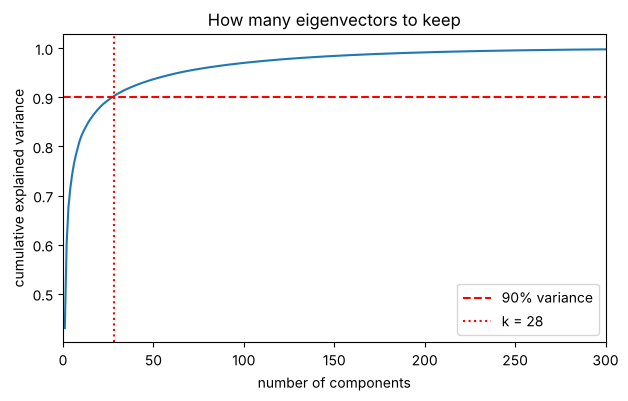

In [2]:
# 2. Pick the two classes, crop and resize every image, then PCA
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.decomposition import PCA

CLASSES = {0: "T-shirt", 6: "shirt"}       # Fashion-MNIST label -> name
PER_CLASS = 500                            # 500 + 500 = 1000 images (>= 200 required)
CROP = 2                                   # trim 2 px of empty border on each side
SIZE = 32                                  # then resize to 32 x 32 = 1,024 numbers

def crop_and_resize(a):
    img = Image.fromarray(a)
    img = img.crop((CROP, CROP, 28 - CROP, 28 - CROP))          # 28x28 -> 24x24
    img = img.resize((SIZE, SIZE), Image.Resampling.BILINEAR)   # 24x24 -> 32x32
    return np.asarray(img, dtype=np.float32) / 255.0

images, labels = [], []
for new_label, (fm_label, name) in enumerate(CLASSES.items()):
    idx = np.where(all_labels == fm_label)[0][:PER_CLASS]
    images += [crop_and_resize(all_images[i]) for i in idx]
    labels += [new_label] * len(idx)
    print(f"{name}: {len(idx)} images")
NAMES = list(CLASSES.values())             # index 0 = T-shirt, 1 = shirt

images = np.array(images)
y = np.array(labels)
X = images.reshape(len(images), -1)        # flatten: one row per image
print("images:", images.shape, " X:", X.shape, " per class:", np.bincount(y))

# How many eigenvectors? Smallest k that keeps 90% of the variance
pca_full = PCA().fit(X)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
k = int(np.argmax(cum_var >= 0.90) + 1)
for n in [10, 50, 100]:
    print(f"{n:>4} components keep {cum_var[n - 1]:.1%} of the variance")
print(f"components for 90% variance: k = {k}  (out of {X.shape[1]} original dimensions)")

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(cum_var) + 1), cum_var)
plt.axhline(0.90, color="r", linestyle="--", label="90% variance")
plt.axvline(k, color="r", linestyle=":", label=f"k = {k}")
plt.xlim(0, 300)
plt.xlabel("number of components")
plt.ylabel("cumulative explained variance")
plt.title("How many eigenvectors to keep")
plt.legend()
plt.savefig("1_explained_variance.png", dpi=150, bbox_inches="tight")
plt.show()


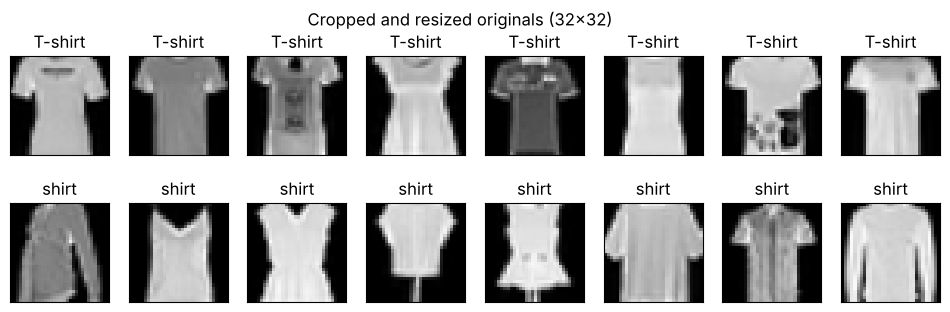

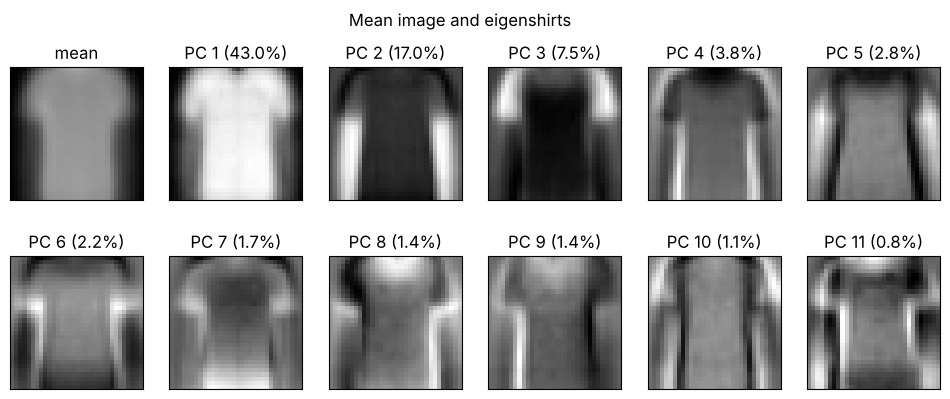

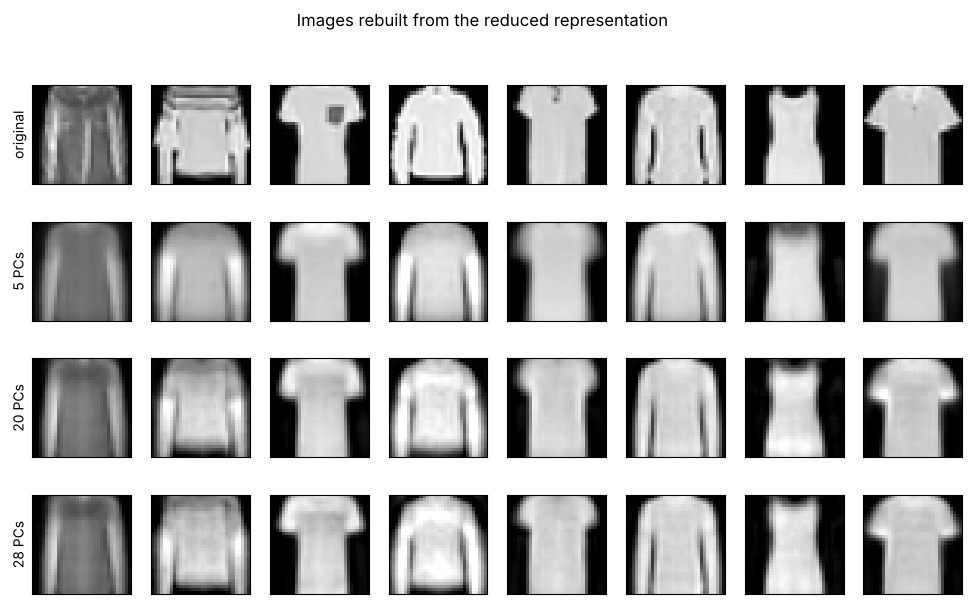

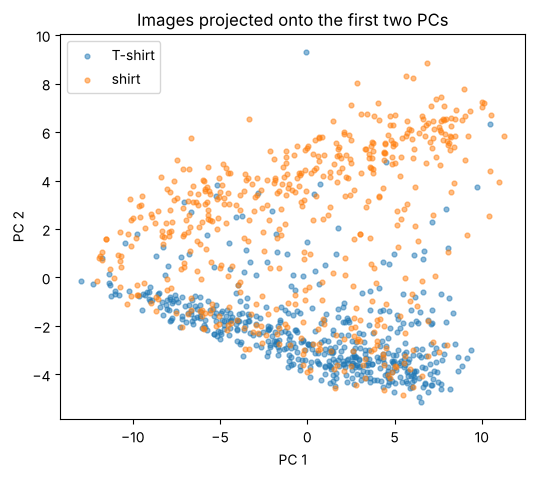

In [3]:
# 3. Visualizations: originals, eigenshirts, reconstructions, PC scatter
def show(ax, v, title=None, rescale=False):
    v = v.reshape(SIZE, SIZE)
    if rescale:
        v = (v - v.min()) / (v.max() - v.min())   # eigenvectors have +/- values
    ax.imshow(v, cmap="gray", vmin=0, vmax=1)
    if title:
        ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])

# Sample of the cropped and resized originals
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
rng = np.random.RandomState(1)
for row in range(2):
    for col, i in enumerate(rng.choice(np.where(y == row)[0], 8, replace=False)):
        show(axes[row, col], images[i], NAMES[row])
fig.suptitle(f"Cropped and resized originals ({SIZE}x{SIZE})")
plt.savefig("2_originals.png", dpi=150, bbox_inches="tight")
plt.show()

# Mean image and the first eigenshirts
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
show(axes[0, 0], pca_full.mean_, "mean")
for i, ax in enumerate(axes.flat[1:]):
    show(ax, pca_full.components_[i], f"PC {i + 1} ({pca_full.explained_variance_ratio_[i]:.1%})", rescale=True)
fig.suptitle("Mean image and eigenshirts")
plt.savefig("3_eigenshirts.png", dpi=150, bbox_inches="tight")
plt.show()

# What the images look like in the reduced representation
def reconstruct(n):
    p = PCA(n).fit(X)
    return np.clip(p.inverse_transform(p.transform(X)), 0, 1)

levels = [5, 20, k]
recs = {n: reconstruct(n) for n in levels}
idx = np.random.RandomState(0).choice(len(X), 8, replace=False)
fig, axes = plt.subplots(len(levels) + 1, 8, figsize=(12, 1.7 * (len(levels) + 1)))
for col, i in enumerate(idx):
    show(axes[0, col], images[i])
    for row, n in enumerate(levels, start=1):
        show(axes[row, col], recs[n][i])
axes[0, 0].set_ylabel("original")
for row, n in enumerate(levels, start=1):
    axes[row, 0].set_ylabel(f"{n} PCs")
fig.suptitle("Images rebuilt from the reduced representation")
plt.savefig("4_reconstructions.png", dpi=150, bbox_inches="tight")
plt.show()

# The data in the first two principal components
Z = pca_full.transform(X)
plt.figure(figsize=(6, 5))
for label in range(2):
    plt.scatter(Z[y == label, 0], Z[y == label, 1], alpha=0.5, s=12, label=NAMES[label])
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("Images projected onto the first two PCs")
plt.legend()
plt.savefig("5_pc_scatter.png", dpi=150, bbox_inches="tight")
plt.show()


In [4]:
#OLS
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# Same split for both classifiers, stratified so both classes are balanced
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y)
COMPONENTS = sorted({2, 5, 10, 20, 50, k}) + [None]   # None = raw pixels, no PCA

def project(n_components):
    """PCA fitted on the training images only, so no test information leaks in."""
    if n_components is None:
        return X_train, X_test
    pca = PCA(n_components).fit(X_train)
    return pca.transform(X_train), pca.transform(X_test)

def ols_classifier(n_components):
    Z_train, Z_test = project(n_components)
    ols = LinearRegression().fit(Z_train, y_train)   # minimizes sum of squared errors
    pred_train = (ols.predict(Z_train) >= 0.5).astype(int)
    pred_test = (ols.predict(Z_test) >= 0.5).astype(int)
    return accuracy_score(y_train, pred_train), accuracy_score(y_test, pred_test), pred_test

print("OLS (squared loss) classifier")
print(f"{'components':>12} {'train acc':>10} {'test acc':>10}")
ols_test = []
for n in COMPONENTS:
    tr, te, _ = ols_classifier(n)
    ols_test.append(te)
    print(f"{'raw pixels' if n is None else n:>12} {tr:>10.3f} {te:>10.3f}")

_, _, pred_k = ols_classifier(k)
print(f"\nConfusion matrix with k = {k} components (rows = true {NAMES}, cols = predicted):")
print(confusion_matrix(y_test, pred_k))


OLS (squared loss) classifier
  components  train acc   test acc
           2      0.805      0.776


           5      0.820      0.780
          10      0.824      0.792
          20      0.833      0.812


          28      0.840      0.800


          50      0.856      0.784
  raw pixels      1.000      0.632



Confusion matrix with k = 28 components (rows = true ['T-shirt', 'shirt'], cols = predicted):
[[112  13]
 [ 36  89]]


Logistic regression (log loss) classifier
  components  train acc   test acc  test logloss


           2      0.812      0.780         0.483


           5      0.817      0.796         0.451


          10      0.821      0.804         0.453


          20      0.836      0.796         0.441


          28      0.845      0.796         0.451
          50      0.861      0.788         0.472


  raw pixels      0.932      0.792         0.470



Confusion matrix with k = 28 components (rows = true ['T-shirt', 'shirt'], cols = predicted):
[[110  15]
 [ 36  89]]


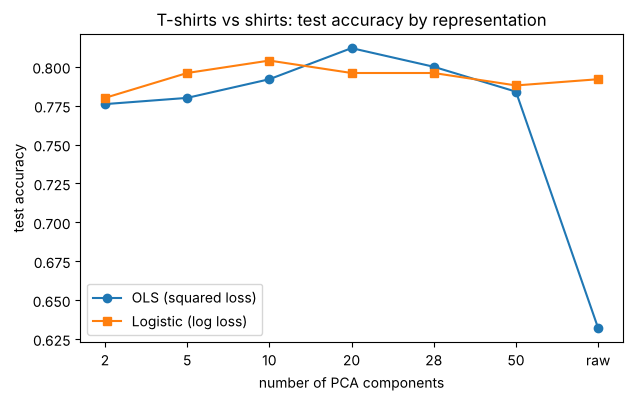

In [5]:
#Log Loss
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

def logistic_classifier(n_components):
    Z_train, Z_test = project(n_components)
    clf = LogisticRegression(max_iter=5000).fit(Z_train, y_train)   # minimizes log loss
    p_test = clf.predict_proba(Z_test)[:, 1]
    return (accuracy_score(y_train, clf.predict(Z_train)),
            accuracy_score(y_test, clf.predict(Z_test)),
            log_loss(y_test, p_test),
            clf.predict(Z_test))

print("Logistic regression (log loss) classifier")
print(f"{'components':>12} {'train acc':>10} {'test acc':>10} {'test logloss':>13}")
log_test = []
for n in COMPONENTS:
    tr, te, ll, _ = logistic_classifier(n)
    log_test.append(te)
    print(f"{'raw pixels' if n is None else n:>12} {tr:>10.3f} {te:>10.3f} {ll:>13.3f}")

_, _, _, pred_k = logistic_classifier(k)
print(f"\nConfusion matrix with k = {k} components (rows = true {NAMES}, cols = predicted):")
print(confusion_matrix(y_test, pred_k))

# Compare both losses
names = [("raw" if n is None else str(n)) for n in COMPONENTS]
xs = np.arange(len(names))
plt.figure(figsize=(7, 4))
plt.plot(xs, ols_test, "o-", label="OLS (squared loss)")
plt.plot(xs, log_test, "s-", label="Logistic (log loss)")
plt.xticks(xs, names)
plt.xlabel("number of PCA components")
plt.ylabel("test accuracy")
plt.title("T-shirts vs shirts: test accuracy by representation")
plt.legend()
plt.savefig("6_classifier_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()
